# **AI METHODS I**
## Day I: Data cleaning and Exploratory Data Analysis (EDA)

## 0.0 Title / Team / Date
- **Title: AI Usage and Impact on Students and Professionals**
- **Team 1: Jerome, Amelia, Sahil, Kazuko**
- **Date: 19th October 2026**

In [11]:
import pandas as pd

## 0.1 The general libraries for this notebook.

| Library | What we use it for |
|---|---|
| `pandas` (`pd`) | Tables (**DataFrames**): loading, filtering, cleaning, grouping |
| `numpy` (`np`) | Fast maths on arrays, and `np.nan` (the "missing value" marker) |
| `matplotlib.pyplot` (`plt`) | The base plotting library: figures, axes, titles, saving images |
| `seaborn` (`sns`) | Statistical plots on top of matplotlib, with nicer defaults and less code |
| `kagglehub` (`kh`) | Downloading datasets directly from [Kaggle](https://www.kaggle.com) |
| `pathlib.Path` | Building file paths that work on Windows, macOS, Linux and Colab |
| `scikit-learn` | The machine learning library of the course. Today only for **imputation** (section 1.10); we import it there |

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

c:\Users\ameli\1-day-assignment\.venv-1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# --- Folders --------------------------------------------------------------
DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here
DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

# --- pandas display options -------------------------------------------------
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# --- plot style -------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

## 0.3 Dataset from kaggle 

In [ ]:
# Download (or reuse from the cache) the CSV file and get its path on our computer
csv_path = kh.dataset_download(
    "eishatuzzuhra/ai-usage-and-impact-on-students-and-professionals",     # dataset handle: owner/dataset-name
    path="AI_Usage_and_Impact_on_Students_and_Professionals.csv",       # file name inside the Kaggle dataset
)

# If Kaggle sent the file zipped (and it was not unzipped), pandas unzips it while reading
is_zip = zipfile.is_zipfile(csv_path)
df = pd.read_csv(csv_path, compression="zip" if is_zip else None)

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 300 rows and 19 columns


In [ ]:
raw_path = DATA_DIR / "AI_Usage_and_Impact_on_Students_and_Professionals.csv"

# Writing 100+ MB takes a few seconds, so we only do it the first time
if not raw_path.exists():
    df.to_csv(raw_path, index=False)  # index=False: do not write pandas' row numbers as an extra column
    print(f"Raw data saved to {raw_path}")
else:
    print(f"Raw data already saved in {raw_path}")

Raw data saved to data\AI_Usage_and_Impact_on_Students_and_Professionals.csv


## 0.4 Dataset card


| | |
|---|---|
| **Name** | AI Usage and Impact on Students & Professionals |
| **Source** | Kaggle, [eishatuzzuhra/ai-usage-and-impact-on-students-and-professionals](https://www.kaggle.com/datasets/eishatuzzuhra/ai-usage-and-impact-on-students-and-professionals) |
| **Origin** |Not documented on the Kaggle page. The data looks self-reported (survey-style), and possibly synthetic |
| **Unit of observation** |One row = one person (a student or a professional) using an AI tool|
| **Size (raw)** |301 rows × 19 columns |
| **Target for Day 2** | `AI usage and impact for architecture industry`:No prediction target. Main question: how do AI tool, usage hours and user type relate to productivity, satisfaction and time saved?|
| **Licence** | CC0: Public Domain MIT License
| **Known limitations** |Small sample (300 rows, about 288 after removing duplicates); self-reported scores; unclear how the data was collected; text mixed into numeric columns; inconsistent spellings; some impossible values (age 97, 23 AI hours/day); some missing values; professions in several languages| 

## 0.5 First look at the data

| Command | What it tells us |
|---|---|
| `df.shape` | Number of rows and columns |
| `df.head()` | The first rows: what the values look like |
| `df.info()` | Column names, data types and how many values are *not* missing |
| `df.describe()` | Summary statistics (mean, min, max, quartiles…) |

In [ ]:
# The first 5 rows. Look carefully at the values: are the numbers really numbers?
df.head()

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.30,4.00,7.00,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.90,3.00,9.00,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.20,2.00,4.00,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.60,4.00,5.00,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.70,4.00,7.00,9.2,6.2,Yes


In [ ]:
# Column names, data types (Dtype) and number of non-missing values per column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    str    
 1   Age                          277 non-null    str    
 2   Gender                       290 non-null    str    
 3   Country                      290 non-null    str    
 4   User_Type                    300 non-null    str    
 5   Education_Level              287 non-null    str    
 6   Profession                   285 non-null    str    
 7   Monthly_Income               290 non-null    str    
 8   AI_Tool                      289 non-null    str    
 9   AI_Purpose                   287 non-null    str    
 10  AI_Usage_Hours_Per_Day       293 non-null    str    
 11  Tasks_Performed              282 non-null    str    
 12  Monthly_AI_Cost              288 non-null    str    
 13  Productivity_Score           28

**What we noticed**
- 3 columns are **numeric** (`float64`). 16 are stored as **text** (`str`). 
- The **Non-Null Count** varies a lot between columns.

In [ ]:
# .T transposes the table (rows <-> columns) so it is easier to read with many columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
User_ID,300,288,U0138,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,277,52,23,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,290,11,Male,122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,290,20,India,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
User_Type,300,2,Student,158,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education_Level,287,16,Bachelor's,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profession,285,126,English Literature Student,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly_Income,290,233,0,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI_Tool,289,16,ChatGPT,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI_Purpose,287,8,Coding,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data dictionary

| Column | Meaning | Architectural reading | Problem spotted |
|---|---|---|---|
| `User_ID` | ID number for each user | – | – |
| `Age` |age of user  | – | missing |
| `Gender` |Female or Male | – |inconsistent text |
| `Country` |Country where user belongs to  |  |  |
| `User_Type` |student or professional | | – |
| `Education_Level` |education status or qualification  | | missing |
| `Profession` |what they study or which industry each user belongs to | |incorrect spelling |
| `Monthly_Income` |currency recieved monthly |  |no description for currency |
| `AI-tool` |ChatGPT, Microsoft Copilot, Perplexity AI, Google Gemini, DeepSeek, ChatGPT | |different usages so hours are not consistance |
| `AI_Purpose` |coding, writing, research, content creation, data analysis, customer support, or office work| |missing |
| `AI_Usage_Hours_Per_Day` |Hours per day the user spends using AI tools | |Spelling variations |
| `Tasks_Performed` |User does with AI | |long description|
| `Monthly_AI_Cost` |Money user spends on AI tools each month | | |
| `Productivity_Score` |Productivity score reported | | |
| `Accuracy_Rating` |How accurate the user finds the AI | | |
| `Satisfaction_Score` |How satisfied the user is with AI | | |
| `Time_Saved_Hours_Per_Week` |Hours per week user says AI saves them | | |
| `Work_or_Study_Hours_Per_Day` |Hours per day user spends working or studying | | |
| `Would_Recommend` |Whether user would recommend AI to others | | |

### Data dictionary (cleaned data) attempt 01

| Column | Meaning | Architectural reading | Problem spotted |
|---|---|---|---|
| `User_ID` | ID number for each user | – | 12 duplicated rows (300 rows but only 288 unique IDs) ; removed |
| `Age` | Age of the user in years | Age group of users the design is for | Text with "yrs", missing, unrealistic values (97) |
| `Gender` | Female, Male, Other, or Non-Binary | Who the useres are (demographic profile) | Inconsistent text (FEMALE, M, F), missing |
| `Country` | Country the user belongs to | Context: Culture, climate region, and how workspaces are used | Inconsistent capitals and spellings (brazil, U.K.), missing |
| `User_Type` | Student or Professional | Type of space: study space (students) or workplace (professional) | – |
| `Education_Level` | Education status or qualification | skills of user | Missing, inconsistent text (Bachelors, HS, Ph.D.) |
| `Profession` | What they study or which industry they work in | Activity or occupation, shapes kind of workspace needed | Missing, mixed languages (Portuguese and English) |
| `Monthly_Income` | Monthly income of the user | The budget users can afford | No currency stated, "$" and commas in text, one unrealistic value (250,000) |
| `AI_Tool` | Main AI tool the user uses | Digital tools used in daily routine | Spelling variations (Chat GPT, chatgpt), missing |
| `AI_Purpose` | What the user uses AI for | Main activity the user does | Missing |
| `AI_Usage_Hours_Per_Day` | Hours of AI use per day | Time spend on digital work each day | "hrs" in text, missing, one impossible value (23) |
| `Tasks_Performed` | What the user does with AI, in their own words | List of what happens in the space | Long free text, missing |
| `Monthly_AI_Cost` | Monthly spending on AI tools | Expenditure on digital tools | "$" in text, missing |
| `Productivity_Score` | Productivity score (values range from 1.6 to 10) | How work setup performs as the user reports it | Missing |
| `Accuracy_Rating` | Rating of how accurate the AI is (values range from 2 to 5) | The user's trust in their tools | Missing |
| `Satisfaction_Score` | Satisfaction with the AI tool (values range from 3 to 10) | Overall user experience and satisfaction after use | Missing |
| `Time_Saved_Hours_Per_Week` | Hours saved per week by using AI | Efficiency gained | "hrs" in text, missing |
| `Work_or_Study_Hours_Per_Day` | Hours worked or studied per day | Hours spent in a space each day | "hrs" in text, missing, one impossible value (20) |
| `Would_Recommend` | Yes, No, or Maybe | Overall opinion on experience | Missing |

### Data dictionary (cleaned data)

| Column | Meaning | Architectural reading | Problem spotted |
|---|---|---|---|
| `User_ID` | ID number for each user | – | 12 duplicated rows (300 rows but only 288 unique IDs); removed |
| `Age` | Age of the user in years | Age group of the users the design is for | Text with "yrs", missing, unrealistic values (97) |
| `Gender` | Female, Male, Other, or Non-Binary | Who the users are (demographic profile) | Inconsistent text (FEMALE, M, F), missing |
| `Country` | Country the user belongs to | Context: culture, climate region, and how workspaces are used | Inconsistent capitals and spellings (brazil, U.K.), missing |
| `User_Type` | Student or Professional | Type of space: study space (student) or workplace (professional) | – |
| `Education_Level` | Education status or qualification | Skills and background of the user | Missing, inconsistent text (Bachelors, HS, Ph.D.) |
| `Profession` | What they study or which industry they work in | Activity or occupation, which shapes the kind of workspace needed | Missing, mixed languages (Portuguese and English) |
| `Monthly_Income` | Monthly income of the user | The budget users can afford | No currency stated, "$" and commas in text, one unrealistic value (250,000) |
| `AI_Tool` | Main AI tool the user uses | Digital tools used in the daily routine | Spelling variations (Chat GPT, chatgpt), missing |
| `AI_Purpose` | What the user uses AI for | Main activity the user does | Missing |
| `AI_Usage_Hours_Per_Day` | Hours of AI use per day | Time spent on digital work each day | "hrs" in text, missing, one impossible value (23) |
| `Tasks_Performed` | What the user does with AI, in their own words | List of what happens in the space | Long free text, several tasks in one cell, missing |
| `Monthly_AI_Cost` | Monthly spending on AI tools | Expenditure on digital tools | "$" in text, missing |
| `Productivity_Score` | Productivity score (values range from 1.6 to 10) | How the work setup performs, as the user reports it | Missing |
| `Accuracy_Rating` | Rating of how accurate the AI is (values range from 2 to 5) | The user's trust in their tools | Missing |
| `Satisfaction_Score` | Satisfaction with the AI tool (values range from 3 to 10) | Overall user experience and satisfaction after use | Missing |
| `Time_Saved_Hours_Per_Week` | Hours saved per week by using AI | Efficiency gained | "hrs" in text, missing |
| `Work_or_Study_Hours_Per_Day` | Hours worked or studied per day | Hours spent in a space each day | "hrs" in text, missing, one impossible value (20) |
| `Would_Recommend` | Yes, No, or Maybe | Overall opinion of the experience | Missing |

In [14]:
# Checks for unrealistic values in Age and Work_or_Study_Hours_Per_Day
age_numbers = pd.to_numeric(df["Age"].astype("string").str.replace(" yrs", "", regex=False), errors="coerce")
work_hours = pd.to_numeric(df["Work_or_Study_Hours_Per_Day"].astype("string").str.replace(" hrs", "", regex=False), errors="coerce")
print("Oldest age:", age_numbers.max())
print("Most work or study hours per day:", work_hours.max())

Oldest age: 97
Most work or study hours per day: 20.0


In [9]:
import pandas as pd

df = pd.read_csv("AI_Usage_and_Impact_on_Students_and_Professionals.csv")
df_clean = df.copy()

# Make all column names lowercase so they are consistent and easy to type
df_clean.columns = df_clean.columns.str.lower()
df_clean.columns.tolist()
#cleaning names since pandas does not understand when things are not the same size.

['user_id',
 'age',
 'gender',
 'country',
 'user_type',
 'education_level',
 'profession',
 'monthly_income',
 'ai_tool',
 'ai_purpose',
 'ai_usage_hours_per_day',
 'tasks_performed',
 'monthly_ai_cost',
 'productivity_score',
 'accuracy_rating',
 'satisfaction_score',
 'time_saved_hours_per_week',
 'work_or_study_hours_per_day',
 'would_recommend']

In [10]:
%pip install matplotlib seaborn kagglehub

  Using cached kagglehub-1.0.2-py3-none-any.whl.metadata (40 kB)
  Using cached kagglesdk-0.1.37-py3-none-any.whl.metadata (13 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 680.1 kB/s eta 0:00:14
   --- ------------------------------------ 0.8/9.5 MB 880.8 kB/s eta 0:00:10
   --- ------------------------------------ 0.8/9.5 MB 880.8 kB/s eta 0:00:10
   ---- ----------------------------------- 1.0/9.5 MB 857.9 kB/s eta 0:00:10
   ----- ---------------------------------- 1.3/9.5 MB 854.9 kB/s eta 0:00:10
   ----- ----

# 1. Data cleaning

1. Tidy column names
2. Remove duplicates
3. Get an overview of missing values
4. Drop useless columns
5. Fix data types (text → numbers)
6. Engineer new features
7. Clean the categorical columns
8. Understand the price columns
9. Handle outliers
10. Handle the remaining missing values
11. Final check and save

In [ ]:
# .copy() creates an independent copy: changing df_clean will NOT change df
df_clean = df.copy()

## 1.1 Tidy column names
 
 Column names are consistent for this dataset; thus we skip this cleanig process.

## 1.2 Duplicates
There are 12 duplicated rows according to pandas.

In [ ]:
# .duplicated() returns True for every row that is an exact copy of an earlier row
n_duplicates = df_clean.duplicated().sum()   # True counts as 1, False as 0
print(f"Exact duplicated rows: {n_duplicates:,}")

Exact duplicated rows: 12


In [ ]:
print(df[df.duplicated()])

    User_ID     Age  Gender         Country     User_Type Education_Level  \
67    U0116      20    Male           India       Student   Undergraduate   
87    U0059      22    Male          Canada  Professional     High School   
137   U0244      26  Female   United States       Student        Master'S   
164   U0279      35    Male       Australia  Professional      Bachelor'S   
170   U0138  16 yrs  Female          Canada       Student        Master'S   
179   U0254      46  Female  United Kingdom  Professional      Bachelor'S   
235   U0055      30    Male     Philippines  Professional         Masters   
238   U0151      39  Female           India  Professional        Master'S   
251   U0085      17  Female          Canada       Student             Phd   
267   U0280  28 yrs  Female          Brazil       Student        Master'S   
268   U0188      27    Male          France       Student     High School   
271   U0104      26    Male        Pakistan       Student             NaN   

In [ ]:
# ...existing code...
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
# ...existing code...

In [ ]:
print(f"Rows after removing exact duplicates: {len(df_clean):,}")

Rows after removing exact duplicates: 288


In [ ]:
# Is the index column unique? (every value different)
print(f"Is 'User_ID' unique? {df_clean['User_ID'].is_unique}")

# Look for duplicates in all the other columns
n_duplicates = df_clean.drop(columns="User_ID").duplicated().sum()
share = n_duplicates / len(df_clean)
print(f"Duplicated rows when ignoring 'User_ID': {n_duplicates:,} ({share:.0%} of the dataset!)")


Is 'User_ID' unique? False
Duplicated rows when ignoring 'User_ID': 12 (4% of the dataset!)


12 rows are identical. So we:
1. **Remove the duplicates** with `drop_duplicates()`, which keeps the first copy of each row.
2. **Reset the row numbers** with `reset_index(drop=True)` so they go 0, 1, 2… again.

In [ ]:
rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print(f"Rows before: {rows_before:,}")
print(f"Rows after:  {len(df_clean):,}")
print(f"Removed:     {rows_before - len(df_clean):,} duplicated rows")

Rows before: 300
Rows after:  288
Removed:     12 duplicated rows


## 1.3 Missing values overview


In [ ]:
def missing_report(data):
    # Return a table with the number and percentage of missing values per column,
    # sorted from most to least missing.
    n_missing = data.isna().sum()                   # count of NaN per column
    pct_missing = data.isna().mean() * 100          # mean of True/False = share of NaN
    report = pd.DataFrame({"n_missing": n_missing, "pct_missing": pct_missing})
    return report.sort_values("pct_missing", ascending=False)


missing = missing_report(df_clean)
missing

,n_missing,pct_missing
Age,23,7.99
Tasks_Performed,17,5.90
Profession,14,4.86
Productivity_Score,14,4.86
Accuracy_Rating,14,4.86
AI_Purpose,13,4.51
Monthly_AI_Cost,12,4.17
Education_Level,12,4.17
Gender,10,3.47
Time_Saved_Hours_Per_Week,10,3.47


Figure saved to figures\01_missing_values.png


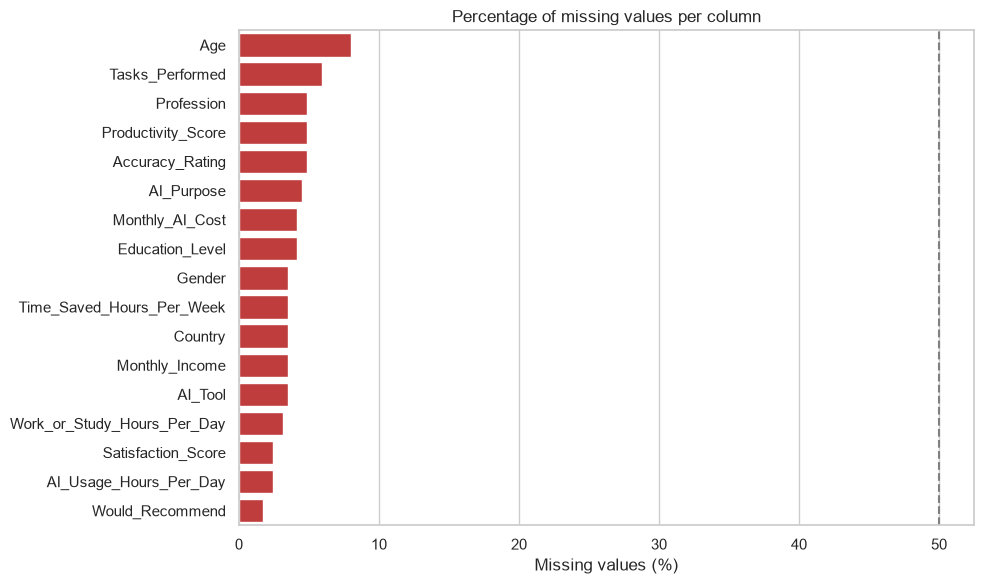

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

In [ ]:
print(df[])

**Reading the chart:**
- Every category has less than 10% of missing values. So we keep every column.
- Core columns like `Satisfaction_Score`, `AI_Usage_Hours_Per_Day` and `WOuld_Recommend` are less than 2-3%.

## 1.4 Drop columns we cannot (or will not) use

We keep every column as it carries information. 

## 1.5 Fix inconsistent data types (text → numbers)

Time is not consitent in columns "Time_Saved_Hours_Per_Week", and "Work_or_Study_Hours_Per_Day". Some are numner only while other are number with text (hrs)

The general strategy:
1. Look at the different formats in the column (`value_counts()`).
2. Write a small **function** that converts *one* value.
3. **Apply** it to the whole column with `.apply()`.
4. **Check** the result.

In [ ]:
# What formats are there? Look at the most frequent values
df_clean["Work_or_Study_Hours_Per_Day"].value_counts().head(10)

Work_or_Study_Hours_Per_Day
6.4    12
7.6     9
7.3     8
5.9     8
6.7     7
6.2     7
7.4     7
7.8     7
8.6     7
8.4     7
Name: count, dtype: int64

In [ ]:
# (\d+) captures the first group of digits; [0] takes that captured group
df_clean["Work_or_Study_Hours_Per_Day"] = pd.to_numeric(
    df_clean["Work_or_Study_Hours_Per_Day"].str.extract(r"(\d+)")[0], errors="coerce"
).astype("Int64")

df_clean["Work_or_Study_Hours_Per_Day"].value_counts(dropna=False).head(8)

Work_or_Study_Hours_Per_Day
6       64
7       55
8       47
5       38
9       25
4       19
10      11
<NA>     9
Name: count, dtype: Int64

In [ ]:
# (\d+) captures the first group of digits; [0] takes that captured group
df_clean["Time_Saved_Hours_Per_Week"] = pd.to_numeric(
    df_clean["Time_Saved_Hours_Per_Week"].str.extract(r"(\d+)")[0], errors="coerce"
).astype("Int64")

df_clean["Time_Saved_Hours_Per_Week"].value_counts(dropna=False).head(8)

Time_Saved_Hours_Per_Week
2    35
5    33
3    30
4    29
7    22
0    22
1    22
6    19
Name: count, dtype: Int64

## 1.6 Feature engineering

We skip feature engineering as given information is sufficient.


## 1.7 Clean the categorical columns

There are inconsistent spelling in column

In [ ]:
for column in ["Gender", "Country", "User_Type", "Education_Level", "Profession", "AI_Purpose"]:
    print(df_clean[column].value_counts(dropna=False), end="\n\n")

Gender
Male          116
Female         99
male           12
Other          12
M              11
NaN            10
F              10
MALE            6
FEMALE          5
other           3
female          3
Non-binary      1
Name: count, dtype: int64

Country
India                       40
United States               33
Canada                      29
Pakistan                    28
United Kingdom              25
Philippines                 23
Brazil                      22
Australia                   19
Nigeria                     17
Germany                     13
NaN                         10
France                       9
Kenya                        6
brazil                       4
india                        3
canada                       2
france                       1
U.K.                         1
United States of America     1
philippines                  1
australia                    1
Name: count, dtype: int64

User_Type
Student         151
Professional    137
Name: count, d

What we will do:
- **Gender**: the spelling is inconsistent. We standardise it to "Female", "Male", "Other", "Non-binary".
- **Country**, **User_Type**, **Education_Level**, **Profession**: the spelling is inconsistent. We standardise it to capital letter.
- **Missing labels**: we fill them with `"Unknown"` instead of guessing.

In [ ]:
# 1-1. First, clean up extra spaces and lowercase everything to make it easier
df["Gender"] = df["Gender"].str.strip().str.lower()

# 1-2. Define a mapping dictionary for variations
gender_mapping = {
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female",
}

# 1-3. Apply the replacement
df["Gender"] = df["Gender"].replace(gender_mapping)

# 2. Strip extra spaces and apply title casing
df["Country"] = df["Country"].str.strip().str.title()

# 3. Strip extra spaces and apply title casing
df["User_Type"] = df["User_Type"].str.strip().str.title()

# 4. Strip extra spaces and apply title casing
df["Education_Level"] = df["Education_Level"].str.strip().str.title()

# 5. Strip extra spaces and apply title casing
df["Profession"] = df["Profession"].str.strip().str.title()

# 6. Fill missing labels with "Unknown"
for column in ["Age", "Gender", "Country","User_Type","Education_Level","Profession", "AI_Tool", "AI_Purpose", "AI_Usage_Hours_Per_Day", "Tasks_Performed" ]:
    df_clean[column] = df_clean[column].fillna("Unknown")

## 1.8 Detective work

Every column is simple and there is no mistery for the dataset although detailed inforation is missing.

## 1.9 Outliers

There is no **outlier** for this dataset.


## 1.10 Handle the remaining missing values


In [ ]:
missing_report(df_clean).head(12)

,n_missing,pct_missing
Productivity_Score,14,4.86
Accuracy_Rating,14,4.86
Monthly_AI_Cost,12,4.17
Time_Saved_Hours_Per_Week,10,3.47
Monthly_Income,10,3.47
Work_or_Study_Hours_Per_Day,9,3.12
Satisfaction_Score,7,2.43
Would_Recommend,5,1.74
Gender,0,0.00
User_ID,0,0.00


Decisions, column by column:

| Column | Missing | Decision | Why |
|---|---|---|---|

# 2. Exploratory Data Analysis (EDA)

Now that the data is clean, we can **explore** it: understand how the values are distributed, how the variables relate to each other, and form hypotheses. EDA is like a first site visit: we walk around before we start designing.

We go from simple to complex:
- **Univariate**: one variable at a time (distributions, counts)
- **Bivariate**: two variables together (is price related to area?)
- **Multivariate**: several variables at once (correlations, grids of plots)

💡 **Tip:** a good EDA plot answers **one question**. Write the question first, then choose the plot.

## 2.1 Descriptive statistics

| Statistic | Meaning |
|---|---|
| **mean** | The average. Sensitive to extreme values |
| **50% (median)** | The middle value: half the listings are below, half above. Robust to extremes |
| **std** | Standard deviation: how spread out the values are |
| **25% / 75%** | Quartiles: the middle 50% of the listings lie between them |
| **skewness** | 0 = symmetric; > 0 = long tail to the right (a few very large values) |

In [ ]:
key_numeric = ["Productivity_Score","Accuracy_Rating","Satisfaction_Score"]

stats = df_clean[key_numeric].describe().T
stats["skewness"] = df_clean[key_numeric].skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
Productivity_Score,274.00,5.24,1.82,1.60,3.90,5.00,6.50,10.00,0.39
Accuracy_Rating,274.00,3.42,0.86,2.00,3.00,3.50,4.00,5.00,-0.14
Satisfaction_Score,281.00,6.13,1.53,3.00,5.00,6.00,7.00,10.00,0.22


## 2.2 Univariate analysis: numerical variables

**Question: how is productivity and satisfaction score distributed?**

Figure saved to figures\02_Productivity_Satisfaction.png


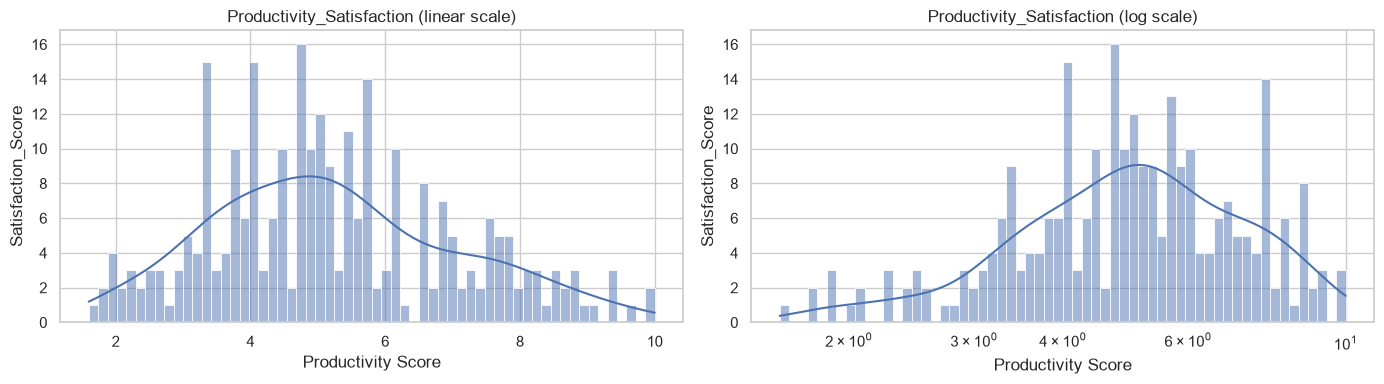

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Linear scale
sns.histplot(df_clean["Productivity_Score"], bins=60, kde=True, ax=axes[0])
axes[0].set_title("Productivity_Satisfaction (linear scale)")
axes[0].set_xlabel("Productivity Score")
axes[0].set_ylabel("Satisfaction_Score")

# Log scale: log_scale=True puts the bins on a logarithmic x axis
sns.histplot(df_clean["Productivity_Score"], bins=60, kde=True, log_scale=True, ax=axes[1])
axes[1].set_title("Productivity_Satisfaction (log scale)")
axes[1].set_xlabel("Productivity Score")
axes[1].set_ylabel("Satisfaction_Score")

plt.tight_layout()
save_fig("02_Productivity_Satisfaction")
plt.show()

## 2.3 Univariate analysis: categorical variables

**Question: which profession spend more time on AI tool? what kind of flats are on the market?**

For categories we **count** how many listings fall in each one, with `sns.countplot()`. Here we draw four plots in a 2×2 grid with `plt.subplots(2, 2)`.

## 2.4 Bivariate analysis: design questions

Now we look at **two variables at a time**. Let's start with the most obvious relation.

**Question: do bigger flats cost more?**

A **scatter plot** shows each listing as a point. With tens of thousands of points the plot becomes a black blob, so we:
- plot a **random sample** of 5,000 listings,
- make the points semi-transparent (`alpha`),
- use **log scales** (both variables are skewed),
- colour the points by typology (`hue="bhk"`).